# Анализ данных о Нобелевских лауреатах

В проекте используем данные Nobel Prize API. Сначала приводим вложенный джейсон к удобному плоскому формату, затем проверяем качество данных и исследуем :

- распределение лауреатов по странам;
- возраст при первом награждении;
- гендерное распределение.

## 1. Подготовка данных

На первом этапе соберём список словарей с информацией о лауреатах и их премиях. Данные о людях и организациях устроены по-разному, а часть полей может отсутствовать, поэтому сначала сделаем универсальные функции для обработки вложенного JSON.

Сначала напишем функции для работы с JSON. данные из API содержат много вложенных словарей и списков, поэтому доставать каждое поле вручную неудобно.

Сделаем:

- функцию, которая получает значение по списку ключей;
- функцию, которая обрабатывает словарь по заданному конфигу;
- функцию для обработки списка словарей;
- функцию, которая создаёт готовый процессор с нужным конфигом.

Если какого-то значения нет, возвращаем `None`, чтобы отсутствие поля не приводило к ошибке.

Проверим, что функции работают правильно. Создадим словарь, где знаем ожидаемые значения.

Проверяем, что функция правильно достаёт вложенные поля, преобразует строки в числа и возвращает `None`, если нужного поля нет. Для проверок используем `assert`: если результат не совпадёт с ожидаемым, получим ошибку.

In [1]:
from json_dict_processing import (
    extract_nested_value,
    process_dictionary_with_config,
    process_list_of_dicts_with_config,
    create_processor
)

test_data = {
    'person': {
        'name': 'Anna',
        'age': '25'
    }
}

test_config = {
    'name': ['person', 'name'],
    'age': (['person', 'age'], int),
    'country': ['person', 'country']
}

assert extract_nested_value(test_data, ['person', 'name']) == 'Anna'
assert extract_nested_value(test_data, ['person', 'country']) is None

expected = {
    'name': 'Anna',
    'age': 25,
    'country': None
}

assert process_dictionary_with_config(test_data, test_config) == expected

assert process_list_of_dicts_with_config(
    [test_data], test_config
) == [expected]

test_processor = create_processor(test_config)

assert test_processor(test_data) == expected

print('Все ок')


Все ок


Используем модуль `core.py`, через который будем импортировать функции обработки JSON. Собираем импорты в одном месте, чтобы дальше не дублировать код.

В модуле `prizes_configs.py` задаём конфиг для обработки информации о премиях, нам нужны год вручения, категория, статус премии и сумма. Для каждого поля указываем путь в JSON, а год переводим из строки в число.

Используем отдельную обработку для списка премий, так как один лауреат мог получить несколько наград.

В `laureates_configs.py` используем отдельные конфиги для людей и организаций, потому что в API информация о них хранится по-разному.

Для людей используем имя, пол, год и страну рождения. Для организаций - название, год и страну основания. В обоих случаях сохраняем `id`, современную страну соответствующего места и информацию о премиях.

Для анализа не нужны конкретные дни и месяцы ==> делаем функцию, которая достаёт из даты только год. Если год неизвестен, возвращаем `None`.

Перед анализом проверяем конфиги на небольших примерах. Смотрим, правильно ли обрабатываются данные человека и организации, извлекаются ли годы из дат и преобразуется ли год получения премии в число.

Отдельно проверяем случаи с пропусками: отсутствие какого-то поля не должно приводить к ошибке.

In [2]:
from laureates_configs import process_person, process_org, process_year

assert process_year('1943-11-07') == 1943
assert process_year('1917-00-00') == 1917
assert process_year('0000-00-00') is None
assert process_year(None) is None


test_person = {
    'id': '1',
    'knownName': {'en': 'Anna'},
    'birth': {'date': '1980-05-10'},
    'nobelPrizes': [
        {
            'awardYear': '2020',
            'category': {'en': 'Physics'}
        }
    ]
}

person = process_person(test_person)

assert person['id'] == 1
assert person['name'] == 'Anna'
assert person['birth_year'] == 1980
assert person['country_birth'] is None
assert person['prizes_relevant'][0]['award_year'] == 2020


test_org = {
    'id': '2',
    'orgName': {'en': 'Example Organization'},
    'founded': {'date': '1950-01-01'}
}

org = process_org(test_org)

assert org['name'] == 'Example Organization'
assert org['founded_year'] == 1950

print('C конфигами все ок')


C конфигами все ок


Теперь загрузим данные о лауреатах через Nobel Prize API. Используем `requests`, проверяем статус ответа и преобразуем его в JSON. Также сравниваем количество загруженных лауреатов с числом из метаданных API, чтобы убедиться, что получили все записи.

In [3]:
import requests
import urllib3

# выключаем предупреждение о сертификате
urllib3.disable_warnings(urllib3.exceptions.InsecureRequestWarning)

URL_LAUREATES = 'https://api.nobelprize.org/2.1/laureates?limit=1200'

REQUEST_HEADERS = {
    'Accept': 'application/json',
    'User-Agent': 'Mozilla/5.0'
}


def load_laureates(url):
    """Загружает данные о лауреатах из Nobel Prize API."""
    response = requests.get(
        url,
        headers=REQUEST_HEADERS,
        timeout=30,
        verify=False
    )

    response.raise_for_status()

    data = response.json()

    assert len(data['laureates']) == int(data['meta']['count'])

    return data


laureates = load_laureates(URL_LAUREATES)

print('Всего лауреатов:', len(laureates['laureates']))

Всего лауреатов: 1028


Делаем функцию, которая определяет тип лауреата и обрабатывает его данные.

В исходном JSON люди и организации отличаются по названиям полей: у людей есть `knownName`, у организаций — `orgName`. По этим полям определяем, какой конфиг использовать.

После обработки добавляем поле `type_`, чтобы дальше можно было разделять людей и организации. Затем применяем функцию ко всем лауреатам и получаем `laureates_data` — список словарей с одинаковой логикой хранения данных.

In [4]:
from laureates_configs import process_org, process_person


def get_laureate_data(laureate):
    """Обрабатывает данные лауреата и добавляет его тип."""
    if 'knownName' in laureate:
        result = process_person(laureate)
        result['type_'] = 'person'

    elif 'orgName' in laureate:
        result = process_org(laureate)
        result['type_'] = 'org'

    else:
        raise ValueError('Не удалось определить тип лауреата')

    return result


laureates_data = []

for laureate in laureates['laureates']:
    laureates_data.append(get_laureate_data(laureate))


### Кратко по этапу 1

- Загрузили данные о Нобелевских лауреатах и привели их к более удобному формату.
- Написали функции для работы с вложенным JSON.
- Сделали отдельные конфиги для людей, организаций и премий.
- Получили готовый датасет `laureates_data`, с которым будем работать дальше.

## 2. Вспомогательные функции для анализа

Логика работы со списком словарей вынесенна в отдельные модули. Будем пользоваться этими функциями.

- `dataset_helpers.py` — фильтрация, группировка, применение агрегаций и технические проверки данных;
- `aggregations.py` — среднее, медиана, максимум, количество и top-N;
- `attribute_manager.py` — добавление новых полей.

Проверим основные функции на примере чтобы убедиться, что группировка, агрегации и добавление новых полей работают ожидаемо до применения к полному датасету.

In [5]:
from dataset_helpers import (
    filter_records,
    group_by_attributes,
    summarize_groups,
    find_duplicate_values,
    find_gaps
)
from aggregations import (
    count_records,
    mean_value,
    median_value,
    max_value,
    top_n
)
from attribute_manager import add_attribute

test_records = [
    {'country': 'USA', 'age': 25},
    {'country': 'UK', 'age': 30},
    {'country': 'USA', 'age': 35}
]

grouped = group_by_attributes(test_records, ['country'])

assert len(grouped[('USA',)]) == 2
assert len(filter_records(test_records, lambda x: x['age'] >= 30)) == 2
assert mean_value(test_records, 'age') == 30
assert median_value(test_records, 'age') == 30
assert max_value(test_records, 'age') == 35
assert top_n(test_records, 'age', 1)[0]['age'] == 35

with_decade = add_attribute(
    test_records,
    'age_decade',
    lambda x: x['age'] // 10 * 10
)

assert with_decade[0]['age_decade'] == 20
assert find_duplicate_values([1, 2, 2, 3, 3]) == [2, 3]
assert find_gaps([1, 2, 5, 6]) == [(2, 5)]

summary = summarize_groups(
    test_records,
    ['country'],
    {'count': count_records}
)

assert sum(row['count'] for row in summary) == len(test_records)

print('с функциями все ок')


с функциями все ок


## 3. Проверка качества данных

Перед основным анализом проведём технический EDA:

- посчитаем общее количество записей, отдельно посмотрим количество людей, организаций и награждений;
- проверим пропуски отдельно для людей, организаций и премий, так как у них разная структура;
- посчитаем количество и долю пропусков;
- найдём минимальный и максимальный `id` и посмотрим годы награждения этих лауреатов;
- проверим повторяющиеся `id`;
- найдём разрывы между соседними `id` больше единицы.

Разрывы сами по себе не обязательно означают ошибку, но их полезно увидеть отдельно.

In [6]:
from dataset_helpers import (
    count_missing,
    calculate_missing_share,
    find_duplicate_values,
    find_gaps
)

people = [x for x in laureates_data if x['type_'] == 'person']
organizations = [x for x in laureates_data if x['type_'] == 'org']

prizes = []

for laureate in laureates_data:
    prizes.extend(laureate['prizes_relevant'])

print('Всего лауреатов:', len(laureates_data))
print('Людей:', len(people))
print('Организаций:', len(organizations))
print('Награждений:', len(prizes))


# Количество и доля пропусков.
datasets = {
    'люди': people,
    'организации': organizations,
    'премии': prizes
}

for name, records in datasets.items():
    missing = count_missing(records)
    missing_share = calculate_missing_share(records)

    print('\n', name)
    print('Количество пропусков:', missing)
    print('Доля пропусков (%):', missing_share)
    print('Все поля заполнены:', all(count == 0 for count in missing.values()))


# Минимальный и максимальный id.
ids = [x['id'] for x in laureates_data]

min_id = min(ids)
max_id = max(ids)

print('\nМинимальный id:', min_id)
print('Максимальный id:', max_id)

# Смотрим, кому принадлежат эти id и в какие годы были награждения.
for laureate in laureates_data:
    if laureate['id'] == min_id or laureate['id'] == max_id:
        years = [
            prize['award_year']
            for prize in laureate['prizes_relevant']
        ]

        print('id:', laureate['id'])
        print('Лауреат:', laureate['name'])
        print('Годы награждения:', years)


# Повторяющиеся id.
duplicates = find_duplicate_values(ids)

print('\nПовторяющиеся id:', duplicates)


# Разрывы между соседними id.
gaps = find_gaps(ids)

print('\nКоличество разрывов:', len(gaps))
print('Пары id с разницей больше 1:', gaps)


Всего лауреатов: 1028
Людей: 1000
Организаций: 28
Награждений: 1036

 люди
Количество пропусков: {'id': 0, 'name': 0, 'gender': 0, 'birth_year': 0, 'country_birth': 3, 'country_now': 3, 'prizes_relevant': 0, 'type_': 0}
Доля пропусков (%): {'id': 0.0, 'name': 0.0, 'gender': 0.0, 'birth_year': 0.0, 'country_birth': 0.3, 'country_now': 0.3, 'prizes_relevant': 0.0, 'type_': 0.0}
Все поля заполнены: False

 организации
Количество пропусков: {'id': 0, 'name': 0, 'founded_year': 1, 'country_founded': 4, 'country_now': 4, 'prizes_relevant': 0, 'type_': 0}
Доля пропусков (%): {'id': 0.0, 'name': 0.0, 'founded_year': 3.57, 'country_founded': 14.29, 'country_now': 14.29, 'prizes_relevant': 0.0, 'type_': 0.0}
Все поля заполнены: False

 премии
Количество пропусков: {'prize_amount': 0, 'prize_amount_adjusted': 0, 'award_year': 0, 'category_en': 0, 'prize_status': 0}
Доля пропусков (%): {'prize_amount': 0.0, 'prize_amount_adjusted': 0.0, 'award_year': 0.0, 'category_en': 0.0, 'prize_status': 0.0}
В

### Кратко по качеству данных

В данных есть поля с пропусками, поэтому дальше перед расчётом конкретной метрики будем явно исключать записи, где нужное значение неизвестно.

Повторяющиеся `id` и разрывы между идентификаторами проверяются отдельно. Разрывы не трактуем автоматически как ошибку: идентификаторы не обязаны образовывать непрерывную последовательность.

## 4. Подготовка данных для анализа

Подготовим несколько дополнительных полей:

- год первой премии каждого лауреата и десятилетие, в которое он её получил;
- для людей рассчитаем примерный возраст на момент первого награждения;
- сделаем отдельные записи для каждой категории, в которой лауреат получал премию. Если один лауреат несколько раз получал премию в одной категории, учитываем его в этой категории только один раз.

Для добавления полей используем готовую функцию `add_attribute`, для группировки — `group_by_attributes`.

In [7]:
from dataset_helpers import (
    filter_records,
    group_by_attributes,
    apply_aggregations,
    summarize_groups
)
from aggregations import (
    count_records,
    mean_value,
    median_value,
    max_value,
    top_n
)
from attribute_manager import add_attribute
import matplotlib.pyplot as plt


# Год первой премии.
data = add_attribute(
    laureates_data,
    'first_award_year',
    lambda x: min(p['award_year'] for p in x['prizes_relevant'])
)

# Десятилетие первой премии.
data = add_attribute(
    data,
    'first_decade',
    lambda x: x['first_award_year'] // 10 * 10
)

# Возраст при первой премии.
data = add_attribute(
    data,
    'age_first_prize',
    lambda x: x['first_award_year'] - x['birth_year']
    if x['type_'] == 'person' and x['birth_year'] is not None
    else None
)


# Создаём отдельные записи для каждой категории лауреата.
category_data = []

for laureate in data:
    groups = group_by_attributes(
        laureate['prizes_relevant'], ['category_en']
    )

    for (category,), prizes in groups.items():
        row = laureate.copy()

        row['category_en'] = category
        row['category_first_year'] = min(
            p['award_year'] for p in prizes
        )
        row['category_decade'] = row['category_first_year'] // 10 * 10

        category_data.append(row)


decades = sorted(set(x['first_decade'] for x in data))
categories = sorted(set(x['category_en'] for x in category_data))

print('Всего лауреатов:', len(data))
print('Записей по категориям:', len(category_data))
print('Категории:', categories)


Всего лауреатов: 1028
Записей по категориям: 1030
Категории: ['Chemistry', 'Economic Sciences', 'Literature', 'Peace', 'Physics', 'Physiology or Medicine']


## 5. Анализ

### 5.1. Распределение лауреатов по странам

Посмотрим, какие страны чаще всего встречаются среди Нобелевских лауреатов.

- Сначала определим топ-5 стран по общему количеству лауреатов.
- Затем составим такие же рейтинги отдельно для каждой категории премии.
- Посмотрим, как менялось количество лауреатов из пяти ведущих стран по десятилетиям.

Для сравнения используем современную страну, соответствующую месту рождения человека или месту основания организации (`country_now`). Это не обязательно страна, где лауреат жил или работал во время награждения.

В динамике учитываем десятилетие первой премии, чтобы один лауреат не попадал в несколько периодов.

Топ-5 стран по количеству лауреатов:
USA - 306
United Kingdom - 96
Germany - 86
France - 66
Japan - 32

Топ-5 стран по категориям:

 Chemistry
USA - 59
Germany - 26
United Kingdom - 26
France - 12
Japan - 9

 Economic Sciences
USA - 56
United Kingdom - 7
Canada - 5
France - 5
the Netherlands - 4

 Literature
France - 12
USA - 10
Sweden - 7
Poland - 7
Germany - 7

 Peace
USA - 26
France - 12
Switzerland - 8
United Kingdom - 7
Russia - 5

 Physics
USA - 71
Germany - 27
United Kingdom - 25
France - 13
Japan - 12

 Physiology or Medicine
USA - 85
United Kingdom - 25
Germany - 20
France - 12
Sweden - 8


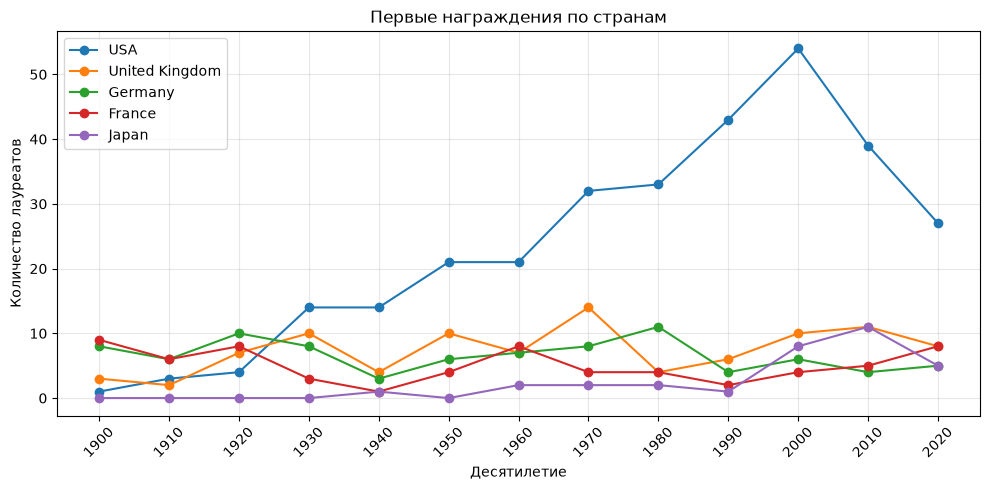

In [8]:
# Оставляем лауреатов с известной страной.
country_data = filter_records(
    data, lambda x: x['country_now'] is not None
)

# Общий рейтинг стран.
country_stats = summarize_groups(
    country_data,
    ['country_now'],
    {'count': count_records}
)

top_countries = top_n(country_stats, 'count', 5)

print('Топ-5 стран по количеству лауреатов:')

for row in top_countries:
    print(row['country_now'], '-', row['count'])


# Топ-5 стран отдельно по каждой категории.
print('\nТоп-5 стран по категориям:')

for category in categories:
    selected = filter_records(
        category_data,
        lambda x: x['category_en'] == category
        and x['country_now'] is not None
    )

    stats = summarize_groups(
        selected,
        ['country_now'],
        {'count': count_records}
    )

    leaders = top_n(stats, 'count', 5)

    print('\n', category)

    for row in leaders:
        print(row['country_now'], '-', row['count'])


# Динамика топ-5 стран по десятилетиям.
country_groups = group_by_attributes(
    country_data, ['country_now', 'first_decade']
)

plt.figure(figsize=(10, 5))

for row in top_countries:
    country = row['country_now']

    counts = []

    for decade in decades:
        count = len(country_groups.get((country, decade), []))
        counts.append(count)

    plt.plot(decades, counts, marker='o', label=country)

plt.title('Первые награждения по странам')
plt.xlabel('Десятилетие')
plt.ylabel('Количество лауреатов')
plt.legend()
plt.grid(alpha=0.3)
plt.xticks(decades, rotation=45)
plt.tight_layout()
plt.show()


### 5.2. Возраст лауреатов при первом награждении

Теперь посмотрим, в каком возрасте люди обычно получают свою первую Нобелевскую премию. Организации в этом анализе учитывать не будем.

- Рассчитаем средний, медианный и максимальный возраст, а также количество лауреатов, для которых возраст известен.
- Сравним средний и медианный возраст по категориям. Учитываем категории премий, полученных в год первого награждения лауреата.
- Посмотрим, как менялся возраст первого награждения по десятилетиям.
- Отдельно выведем пятёрку самых молодых и самых старших лауреатов.

Возраст считаем как разницу между годом получения первой премии и годом рождения, поэтому результат может отличаться от точного возраста максимум на один год.

Общая статистика возраста:
Количество людей: 1000
Средний возраст: 60.6
Медианный возраст: 61.0
Максимальный возраст: 97

Возраст по категориям:
Physics | людей: 230 | средний: 57.8 | медианный: 56.0 | максимальный: 96
Physiology or Medicine | людей: 235 | средний: 59.0 | медианный: 58 | максимальный: 87
Chemistry | людей: 199 | средний: 59.4 | медианный: 58 | максимальный: 97
Peace | людей: 112 | средний: 61.0 | медианный: 62.0 | максимальный: 87
Literature | людей: 123 | средний: 65.0 | медианный: 67 | максимальный: 88
Economic Sciences | людей: 101 | средний: 67.2 | медианный: 67 | максимальный: 90

Возраст по десятилетиям:
1900 | людей: 56 | средний: 57.8 | медианный: 58.0
1910 | людей: 37 | средний: 53.1 | медианный: 50
1920 | людей: 54 | средний: 55.0 | медианный: 56.0
1930 | людей: 55 | средний: 51.6 | медианный: 49
1940 | людей: 40 | средний: 58.0 | медианный: 56.0
1950 | людей: 71 | средний: 54.3 | медианный: 54
1960 | людей: 74 | средний: 56.4 | медианный: 57.0
1970 | людей: 

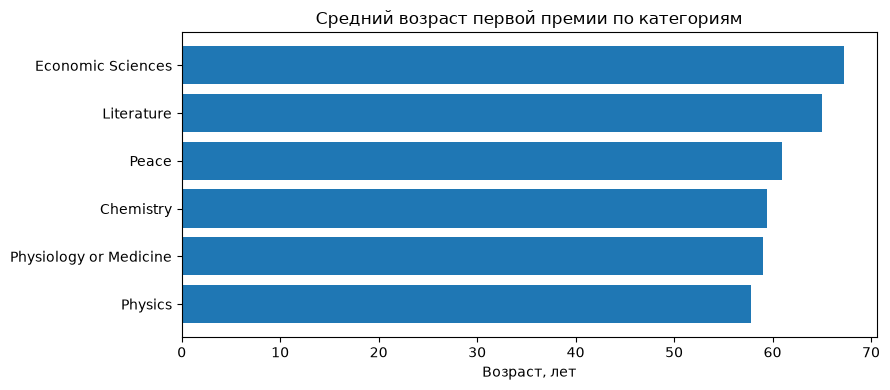

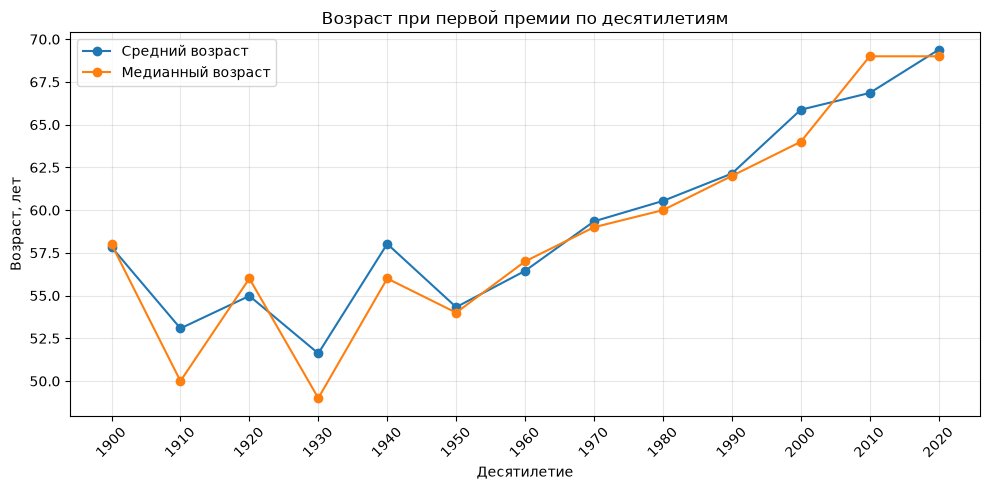

In [9]:
# Оставляем только людей с известным возрастом.
people = filter_records(
    data,
    lambda x: x['type_'] == 'person'
    and x['age_first_prize'] is not None
)

# Функции для расчёта статистик.
age_metrics = {
    'count': count_records,
    'mean': lambda x: mean_value(x, 'age_first_prize'),
    'median': lambda x: median_value(x, 'age_first_prize'),
    'max': lambda x: max_value(x, 'age_first_prize')
}

# Общая статистика.
total_age = apply_aggregations(people, age_metrics)

print('Общая статистика возраста:')
print('Количество людей:', total_age['count'])
print('Средний возраст:', round(total_age['mean'], 1))
print('Медианный возраст:', total_age['median'])
print('Максимальный возраст:', total_age['max'])


# Сравнение категорий.
# Берём категории, в которых лауреат получил премию в год первого награждения.
first_categories = filter_records(
    category_data,
    lambda x: x['type_'] == 'person'
    and x['age_first_prize'] is not None
    and x['category_first_year'] == x['first_award_year']
)

age_by_category = summarize_groups(
    first_categories,
    ['category_en'],
    age_metrics
)

age_by_category = sorted(
    age_by_category, key=lambda x: x['mean']
)

print('\nВозраст по категориям:')

for row in age_by_category:
    print(
        row['category_en'],
        '| людей:', row['count'],
        '| средний:', round(row['mean'], 1),
        '| медианный:', row['median'],
        '| максимальный:', row['max']
    )


# Динамика возраста по десятилетиям.
age_by_decade = summarize_groups(
    people,
    ['first_decade'],
    age_metrics
)

age_by_decade = sorted(
    age_by_decade, key=lambda x: x['first_decade']
)

print('\nВозраст по десятилетиям:')

for row in age_by_decade:
    print(
        row['first_decade'],
        '| людей:', row['count'],
        '| средний:', round(row['mean'], 1),
        '| медианный:', row['median']
    )


# Самые молодые и самые старшие лауреаты.
print('\n5 самых молодых лауреатов:')

for row in top_n(people, 'age_first_prize', 5, reverse=False):
    print(row['name'], '-', row['age_first_prize'], 'лет')

print('\n5 самых старших лауреатов:')

for row in top_n(people, 'age_first_prize', 5):
    print(row['name'], '-', row['age_first_prize'], 'лет')


# График среднего возраста по категориям.
plt.figure(figsize=(9, 4))

plt.barh(
    [x['category_en'] for x in age_by_category],
    [x['mean'] for x in age_by_category]
)

plt.title('Средний возраст первой премии по категориям')
plt.xlabel('Возраст, лет')
plt.tight_layout()
plt.show()


# График динамики среднего и медианного возраста.
plt.figure(figsize=(10, 5))

plt.plot(
    [x['first_decade'] for x in age_by_decade],
    [x['mean'] for x in age_by_decade],
    marker='o',
    label='Средний возраст'
)

plt.plot(
    [x['first_decade'] for x in age_by_decade],
    [x['median'] for x in age_by_decade],
    marker='o',
    label='Медианный возраст'
)

plt.title('Возраст при первой премии по десятилетиям')
plt.xlabel('Десятилетие')
plt.ylabel('Возраст, лет')
plt.legend()
plt.grid(alpha=0.3)
plt.xticks(decades, rotation=45)
plt.tight_layout()
plt.show()


### 5.3. Гендерное распределение лауреатов

В последней части посмотрим, как менялось представительство женщин среди Нобелевских лауреатов.

- Сначала посчитаем общее количество женщин и мужчин, а также долю женщин среди лауреатов с известным полом.
- Сравним количество и долю женщин по категориям.
- Посмотрим, как менялось количество женщин-лауреатов по десятилетиям награждения.
- Отдельно посчитаем количество лауреаток по категориям и десятилетиям.
- Сравним первые и последние 20 лет в датасете, чтобы понять, какие категории лидировали по количеству женщин в начале и в конце рассматриваемого периода.

При подсчёте динамики один человек учитывается не более одного раза внутри каждого десятилетия. При подсчёте по категориям одна женщина также учитывается только один раз внутри категории и периода, даже если получала в нём несколько премий. Доли везде считаем среди лауреатов с известным полом.

Общее гендерное распределение:
Женщин: 69
Мужчин: 931
Пол неизвестен: 0
Доля женщин: 6.9 %

Распределение женщин по категориям:
Economic Sciences | женщин: 3 | доля: 2.97 %
Physics | женщин: 5 | доля: 2.17 %
Chemistry | женщин: 8 | доля: 4.0 %
Literature | женщин: 19 | доля: 15.45 %
Peace | женщин: 21 | доля: 18.58 %
Physiology or Medicine | женщин: 14 | доля: 5.96 %

Женщины по десятилетиям награждения:
1900 | женщин: 3 | доля: 5.36 %
1910 | женщин: 1 | доля: 2.63 %
1920 | женщин: 2 | доля: 3.7 %
1930 | женщин: 3 | доля: 5.45 %
1940 | женщин: 3 | доля: 7.5 %
1950 | женщин: 0 | доля: 0.0 %
1960 | женщин: 3 | доля: 4.0 %
1970 | женщин: 4 | доля: 3.88 %
1980 | женщин: 4 | доля: 4.26 %
1990 | женщин: 7 | доля: 6.93 %
2000 | женщин: 11 | доля: 9.24 %
2010 | женщин: 13 | доля: 11.11 %
2020 | женщин: 16 | доля: 19.51 %

Количество женщин по категориям и десятилетиям:
Декада	Chemistry	Economic Sciences	Literature	Peace	Physics	Physiology or Medicine
1900	0	0	1	1	1	0
1910	1	0	0	0	0	0
1920	0	0	

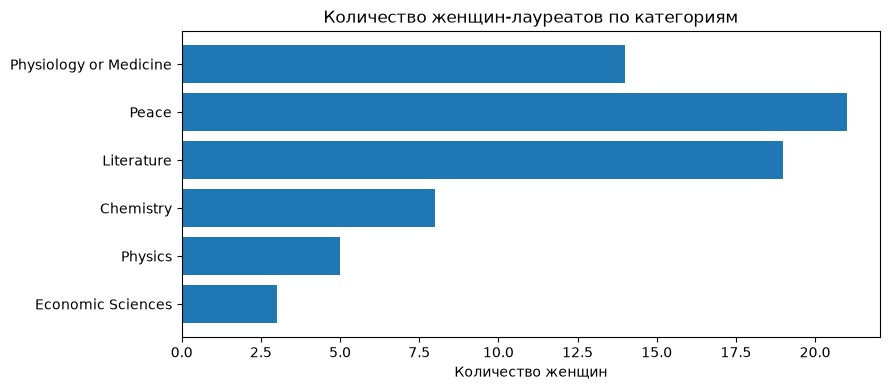

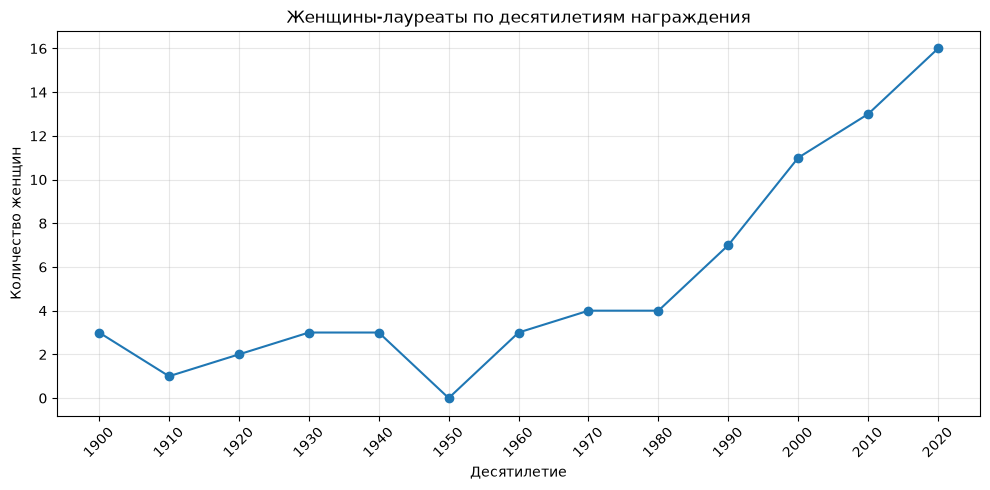

In [10]:
# Оставляем только людей.
all_people = filter_records(
    data, lambda x: x['type_'] == 'person'
)

women = filter_records(
    all_people, lambda x: x['gender'] == 'female'
)

men = filter_records(
    all_people, lambda x: x['gender'] == 'male'
)

known_gender_people = filter_records(
    all_people,
    lambda x: x['gender'] in ('female', 'male')
)

known_gender = len(known_gender_people)

print('Общее гендерное распределение:')
print('Женщин:', len(women))
print('Мужчин:', len(men))
print('Пол неизвестен:', len(all_people) - known_gender)

if known_gender > 0:
    print(
        'Доля женщин:',
        round(len(women) / known_gender * 100, 2),
        '%'
    )


def count_women(records):
    """Считает количество женщин в списке записей."""
    return len(filter_records(
        records, lambda x: x.get('gender') == 'female'
    ))


# Распределение по категориям.
category_people = filter_records(
    category_data,
    lambda x: x['type_'] == 'person'
    and x['gender'] in ('female', 'male')
)

gender_by_category = summarize_groups(
    category_people,
    ['category_en'],
    {
        'people': count_records,
        'women': count_women
    }
)

print('\nРаспределение женщин по категориям:')

for row in gender_by_category:
    share = round(row['women'] / row['people'] * 100, 2)

    print(
        row['category_en'],
        '| женщин:', row['women'],
        '| доля:', share, '%'
    )


# Для динамики создаём отдельную запись для каждого фактического награждения.
person_prizes = []

for person in known_gender_people:
    for prize in person['prizes_relevant']:
        person_prizes.append({
            'id': person['id'],
            'gender': person['gender'],
            'award_year': prize['award_year'],
            'award_decade': prize['award_year'] // 10 * 10,
            'category_en': prize['category_en']
        })

award_decades = sorted(set(
    x['award_decade'] for x in person_prizes
))

# Один человек учитывается не более одного раза внутри десятилетия.
unique_people_by_decade = []

for records in group_by_attributes(
    person_prizes, ['id', 'award_decade']
).values():
    unique_people_by_decade.append(records[0])

gender_by_decade = summarize_groups(
    unique_people_by_decade,
    ['award_decade'],
    {
        'people': count_records,
        'women': count_women
    }
)

gender_by_decade = sorted(
    gender_by_decade, key=lambda x: x['award_decade']
)

print('\nЖенщины по десятилетиям награждения:')

for row in gender_by_decade:
    share = round(row['women'] / row['people'] * 100, 2)

    print(
        row['award_decade'],
        '| женщин:', row['women'],
        '| доля:', share, '%'
    )


# Женщины по категориям и десятилетиям.
women_prizes = filter_records(
    person_prizes,
    lambda x: x['gender'] == 'female'
)

unique_women_by_category_decade = []

for records in group_by_attributes(
    women_prizes, ['id', 'award_decade', 'category_en']
).values():
    unique_women_by_category_decade.append(records[0])

women_groups = group_by_attributes(
    unique_women_by_category_decade,
    ['award_decade', 'category_en']
)

print('\nКоличество женщин по категориям и десятилетиям:')
print('Декада', *categories, sep='\t')

for decade in award_decades:
    counts = []

    for category in categories:
        count = len(women_groups.get((decade, category), []))
        counts.append(count)

    print(decade, *counts, sep='\t')


# Сравниваем первые и последние 20 лет по фактическим годам награждения.
first_year = min(x['award_year'] for x in person_prizes)
last_year = max(x['award_year'] for x in person_prizes)

periods = [
    (first_year, first_year + 19),
    (last_year - 19, last_year)
]

print('\nСравнение первых и последних 20 лет:')

for start, end in periods:
    selected = filter_records(
        women_prizes,
        lambda x: start <= x['award_year'] <= end
    )

    unique_selected = []

    for records in group_by_attributes(
        selected, ['id', 'category_en']
    ).values():
        unique_selected.append(records[0])

    counts = {}

    for category in categories:
        counts[category] = len(filter_records(
            unique_selected,
            lambda x: x['category_en'] == category
        ))

    max_count = max(counts.values())
    leaders = [
        category
        for category in categories
        if counts[category] == max_count
    ]

    print('\nПериод:', start, '-', end)
    print('Женщин по категориям:', counts)
    print('Лидирующие категории:', leaders)


# График количества женщин по категориям.
plt.figure(figsize=(9, 4))

plt.barh(
    [x['category_en'] for x in gender_by_category],
    [x['women'] for x in gender_by_category]
)

plt.title('Количество женщин-лауреатов по категориям')
plt.xlabel('Количество женщин')
plt.tight_layout()
plt.show()


# Динамика по десятилетиям.
plt.figure(figsize=(10, 5))

plt.plot(
    [x['award_decade'] for x in gender_by_decade],
    [x['women'] for x in gender_by_decade],
    marker='o'
)

plt.title('Женщины-лауреаты по десятилетиям награждения')
plt.xlabel('Десятилетие')
plt.ylabel('Количество женщин')
plt.grid(alpha=0.3)
plt.xticks(award_decades, rotation=45)
plt.tight_layout()
plt.show()


## 6. Выводы по результатам анализа

**1. Распределение по странам**

По общему количеству лауреатов лидируют США (306), Великобритания (96) и Германия (86). При этом распределение отличается в зависимости от категории: например, в литературе на первом месте Франция, а в физике, химии и медицине лидируют США.

Общая картина во многом зависит от научных категорий. Также важно учитывать, что мы анализируем современную страну, соответствующую месту рождения или основания, а не гражданство лауреатов.

**2. Возраст при первом награждении**

Средний возраст получения первой премии составляет около 60,6 года, медианный — 61 год. Значения почти совпадают, поэтому в целом среднее не сильно отличается от центрального значения распределения.

При этом между категориями есть заметная разница. Самый высокий средний возраст в экономике — около 67,2 года, а самый низкий в физике — около 57,8 года.

По десятилетиям также заметен рост возраста: в 1930-х средний возраст составлял около 51,6 года, а в 2020-х — уже около 69,4 года. Это может быть связано с тем, что признание научных достижений занимает больше времени, но для подтверждения такой причины потребовалось бы отдельное исследование.

**3. Гендерное распределение**

Среди 1000 лауреатов-людей 69 женщин, то есть 6,9%. Больше всего женщин получали премии мира (21) и литературы (19).

При этом представительство женщин постепенно растёт. В 1900-х женщины составляли около 5,4% лауреатов с известным полом, а в 2020-х — около 19,5%.

В первые 20 лет по одной женщине получили премию в категориях физики, химии, литературы и мира. В последние 20 лет лидируют литература и премия мира — по 9 женщин в каждой категории.

**Общий вывод**

По данным видно, что распределение Нобелевских премий заметно различается по странам, возрасту и полу лауреатов. В целом со временем увеличиваются и средний возраст первого награждения, и доля женщин среди лауреатов.

При интерпретации динамики важно помнить, что последнее десятилетие ещё не завершено, поэтому сравнивать абсолютные количества с полными десятилетиями нужно осторожно.